In [28]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("../data/raw/India_house_detail.csv")

print("Shape:", df.shape)

df.head()

Shape: (260000, 57)


,property_id,listing_date,city,state,city_tier,locality,latitude,longitude,property_type,bhk,...,builder_reputation_score,seller_type,rera_registered,ownership_type,property_tax_annual_inr,maintenance_charges_monthly_inr,days_on_market,is_negotiable,price_inr,price_per_sqft
0,IN0000001,2024-06-20,Jodhpur,Rajasthan,2,Ashok Extension,26.21204,73.03690,Apartment,2,...,6.9,Agent,1,Leasehold,4538.0,4563.0,52,Yes,3807258.0,3458.0
1,IN0000002,2023-12-16,Indore,Madhya Pradesh,2,Hill Phase 1,22.77042,75.86870,Independent House,1,...,7.2,Owner,0,Co-operative Society,4134.0,2977.0,313,Yes,2278968.0,4236.0
2,IN0000003,2024-05-03,Nellore,Andhra Pradesh,3,New Nagar,14.49051,79.99337,Independent House,4,...,5.2,Builder,1,Leasehold,12927.0,5804.0,60,Yes,9655800.0,4598.0
3,IN0000004,2022-04-18,Amritsar,Punjab,2,Vidya Enclave,31.64208,74.75148,Apartment,2,...,6.6,Owner,1,Co-operative Society,5403.0,5364.0,29,Yes,5429476.0,5018.0
4,IN0000005,2023-08-23,Bangalore,Karnataka,1,Golden Extension,13.03995,77.53008,Penthouse,3,...,6.2,Owner,1,Freehold,10569.0,2312.0,54,No,25095400.0,18700.0


In [31]:
df.isna().sum() [df.isna().sum() > 0]

plot_area_sqft          164648
distance_to_metro_km    153652
dtype: int64

In [32]:
df.describe()

,city_tier,latitude,longitude,bhk,super_built_up_area_sqft,carpet_area_sqft,plot_area_sqft,bathrooms,balconies,floor_no,...,distance_to_mall_km,distance_to_it_hub_km,air_quality_index,builder_reputation_score,rera_registered,property_tax_annual_inr,maintenance_charges_monthly_inr,days_on_market,price_inr,price_per_sqft
count,260000.000000,260000.000000,260000.000000,260000.000000,260000.000000,260000.000000,95352.000000,260000.000000,260000.000000,260000.000000,...,260000.000000,260000.000000,260000.00000,260000.000000,260000.000000,260000.000000,260000.000000,260000.000000,2.600000e+05,260000.000000
mean,1.831227,21.027714,78.948749,2.585788,1296.287100,972.344038,2271.560544,2.615462,2.066000,10.253754,...,2.992774,6.993713,112.14190,6.483922,0.648438,7448.470408,4864.716027,182.697854,9.007761e+06,6940.114531
std,0.691880,6.020647,5.525138,0.990450,583.847564,441.818713,1143.014352,1.162751,1.064603,8.866980,...,2.950991,6.886471,41.79884,1.755596,0.477459,4284.343310,2860.849711,105.102554,8.144257e+06,4926.403022
min,1.000000,8.306360,70.589430,1.000000,280.000000,190.000000,309.000000,1.000000,0.000000,0.000000,...,0.100000,0.200000,25.00000,1.000000,0.000000,704.000000,425.000000,1.000000,4.167060e+05,1070.000000
25%,1.000000,17.346350,74.897560,2.000000,890.000000,664.000000,1458.000000,2.000000,1.000000,3.000000,...,0.900000,2.000000,82.00000,5.300000,0.000000,4322.000000,2762.000000,92.000000,4.195515e+06,3940.000000
50%,2.000000,22.270880,77.565300,2.000000,1202.000000,899.000000,2040.000000,3.000000,2.000000,8.000000,...,2.100000,4.900000,111.00000,6.500000,1.000000,6537.000000,4253.000000,183.000000,6.602186e+06,5402.000000
75%,2.000000,25.708375,80.914065,3.000000,1552.000000,1173.000000,2846.250000,3.000000,3.000000,16.000000,...,4.200000,9.700000,141.00000,7.700000,1.000000,9554.000000,6274.000000,274.000000,1.080481e+07,7990.000000
max,3.000000,32.978100,94.130530,5.000000,3549.000000,2886.000000,8428.000000,6.000000,4.000000,39.000000,...,18.000000,40.000000,299.00000,10.000000,1.000000,31049.000000,20147.000000,364.000000,1.346832e+08,52136.000000


## Check Null Value

In [33]:
df.isna().sum() [df.isna().sum() > 0]

plot_area_sqft          164648
distance_to_metro_km    153652
dtype: int64

## Price Distribution

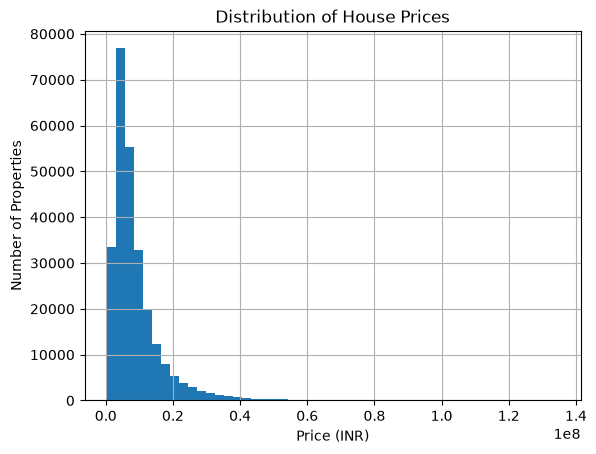

In [34]:
df['price_inr'].hist(bins= 50)
plt.xlabel('Price (INR)')
plt.ylabel('Number of Properties')
plt.title('Distribution of House Prices')
plt.show()

## Price by City Tier

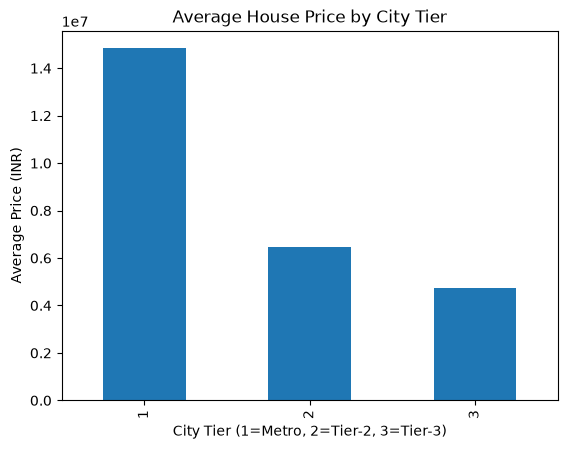

In [35]:
df.groupby('city_tier')['price_inr'].mean().plot(kind='bar')
plt.xlabel('City Tier (1=Metro, 2=Tier-2, 3=Tier-3)')
plt.ylabel('Average Price (INR)')
plt.title('Average House Price by City Tier')
plt.show()

## Price by Property Type

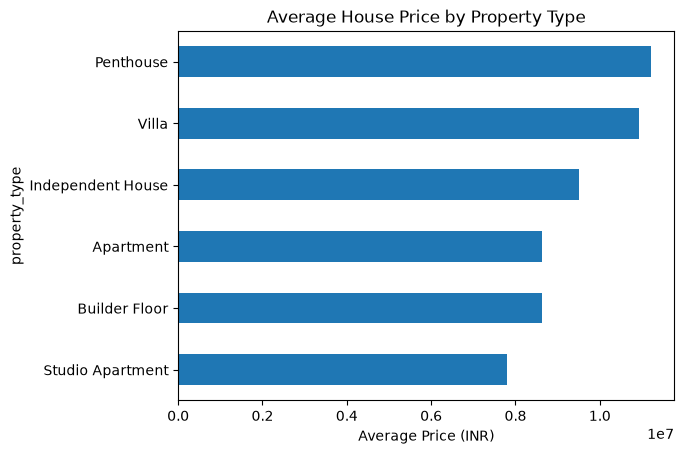

In [36]:
df.groupby('property_type')['price_inr'].mean().sort_values().plot(kind='barh')
plt.xlabel('Average Price (INR)')
plt.title('Average House Price by Property Type')
plt.show()

## Price vs. BHK (bedrooms)

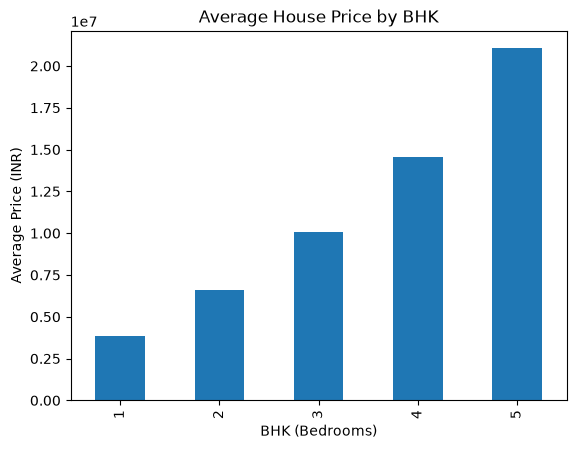

In [44]:
df.groupby('bhk')['price_inr'].mean().plot(kind='bar')
plt.xlabel('BHK (Bedrooms)')
plt.ylabel('Average Price (INR)')
plt.title('Average House Price by BHK')
plt.show()

In [ ]:
# does this property have a plot area at all?
df['has_plot'] = df['plot_area_sqft'].notna().astype(int)           #True = 1, False = 0

print(df['has_plot'].value_counts())

has_plot
0    164648
1     95352
Name: count, dtype: int64


In [40]:
# Now fill the missing plot_area values with 0 (meaning "not applicable")
df['plot_area_sqft'] = df['plot_area_sqft'].fillna(0)

In [ ]:
# Check 
print(df['plot_area_sqft'].isna().sum(), "missing values left")

0 missing values left
